# 01 · Audit of existing detectors: commercial and open-source

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SheridanLu/detecting-the-detector/blob/main/notebooks/01_audit_commercial_and_opensource.ipynb)

**Goal.** Before training our own detectors (notebooks 02-04) we ask the project's question of detectors that already
exist: *do they wrongly flag essays by non-native English writers as AI-written?* We look at seven commercial
detectors and at two open-source "zero-shot" detectors (Binoculars and Fast-DetectGPT), then explain how the two
open-source ones work and run them live on a small sample.

> **WHAT IS REPLAYED, WHAT IS RE-RUN, WHAT IS OFF**
>
> | part | what | status |
> |---|---|---|
> | 1 | 7 commercial detectors (scores archived by Liang et al. in 2023; those versions can no longer be queried) and Binoculars / Fast-DetectGPT with the **falcon-7b** model pair (scored once on the A40 server; needs about 28 GB of GPU memory) | **REPLAYED from saved scores.** Always runs; no model is run. |
> | 2 | the Binoculars score and the Fast-DetectGPT criterion, written out in plain code and run **live** on a small sample | **RE-RUN with STAND-IN small models** (not the falcon-7b pair). Numbers are *not comparable* to the archived ones. |
> | 2 (last cell) | the same two detectors with the real falcon-7b pair | **OFF by default** (FULL mode only, needs a GPU with 40 GB). |
> | 3 | plain-English explanations and the honest limits | text |

| Mode | Part 1 (replay) | Part 2 (live, stand-in models) | GPU |
|---|---|---|---|
| SMOKE | everything, 20 bootstrap resamples | **12 essays**, `gpt2` + `distilgpt2`, on CPU (a few minutes, most of it downloading the models) | no |
| FAST (default) | everything, 200 resamples | **about 200 essays**; on a GPU (Colab T4, fp16) `Qwen2.5-0.5B` + `Qwen2.5-0.5B-Instruct`; on a runtime **without GPU** the notebook automatically uses `gpt2` + `distilgpt2` (the Qwen pair is far too slow on a CPU) | recommended |
| FULL | everything, 1,000 resamples | as FAST, plus the optional falcon-7b cell (off unless you switch it on) | A100 40 GB for the optional cell |

Four words you need (full explanations in Part 3): a **score** is the number a detector gives an essay; a **false
flag** is a human essay called AI; the **false-flag rate** is the share of human essays that get flagged; the
**bias AUC** is the chance that a random non-native essay gets a more AI-like score than a random native one
(0.5 = no bias).

In [1]:
# --- Setup: find the repository (or download it on Colab) and install anything Colab does not have ---
import os, sys, time, pathlib, subprocess
T0 = time.time()
REPO_URL = "https://github.com/SheridanLu/detecting-the-detector"

def _is_repo(p):
    return (p / "ddlib" / "__init__.py").is_file() and (p / "data").is_dir()

def _locate_or_fetch():
    here = pathlib.Path.cwd().resolve()
    for p in [pathlib.Path(os.environ.get("DD_REPO", here)), here, *here.parents]:
        if _is_repo(p):
            return p                                   # mode 1: already inside the repo
    dest = pathlib.Path("/content" if os.path.isdir("/content") else here) / "detecting-the-detector"
    if not _is_repo(dest) and not dest.exists():       # mode 2: git clone (token optional, for a private repo)
        tok = os.environ.get("GH_TOKEN")
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN") or tok
        except Exception:
            pass
        url = REPO_URL.replace("https://", f"https://x-access-token:{tok}@") if tok else REPO_URL
        subprocess.run(["git", "clone", "--depth", "1", "-q", url, str(dest)], env=dict(os.environ, GIT_TERMINAL_PROMPT="0"))
        if tok and dest.exists():
            subprocess.run(["git", "-C", str(dest), "remote", "set-url", "origin", REPO_URL])   # token not kept on disk
    if _is_repo(dest):
        return dest
    return None                                        # mode 3 (zip upload) is handled below

root = _locate_or_fetch()
if root is None:
    # Zip fallback: needs the small ddlib/paths.py helper, which we cannot import yet, so do it here.
    print("Could not find or clone the repository.\n"
          "Fix 1: add a Colab secret GH_TOKEN (key icon, left sidebar) with read access, allow notebook access, re-run.\n"
          f"Fix 2: download the repo as a zip ({REPO_URL} > Code > Download ZIP) and upload it when asked.")
    from google.colab import files
    import zipfile
    up = files.upload()
    zipfile.ZipFile(next(k for k in up if k.endswith(".zip"))).extractall("/content")
    root = next(p.parent.parent for p in pathlib.Path("/content").glob("*/ddlib/__init__.py") if _is_repo(p.parent.parent))
sys.path.insert(0, str(root))
os.chdir(root)                                         # all paths below are relative to the repo root

# requirements-colab.txt: packages for every notebook; requirements-nb01.txt: torch + transformers (preinstalled on Colab)
_req = []
for _f in ("requirements-colab.txt", "requirements-nb01.txt"):
    _req += [l.strip() for l in open(_f) if l.strip() and not l.startswith("#")]
if _req:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *_req], check=True)

from ddlib import get_repo
REPO = get_repo()
print("Python", sys.version.split()[0])

Repository found. Data folder present: True
Python 3.12.16


## Configuration

In [2]:
# --- CONFIG ---------------------------------------------------------------------------------------
# MODE = "SMOKE" (tiny live demo, used for automated testing), "FAST" (default) or "FULL".
# Change the string below to switch. (The DD_MODE environment variable is only used by automated tests.)
MODE = os.environ.get("DD_MODE", "FAST").upper()
assert MODE in ("SMOKE", "FAST", "FULL"), MODE
N_BOOT = {"SMOKE": 20, "FAST": 200, "FULL": 1000}[MODE]     # resamples for the confidence intervals of AUCs (Part 1)

# Part 2: the two small STAND-IN models (they must share one tokenizer) and the live sample
#   sample = (TOEFL essays, native college essays, GPT-3 essays), drawn at random with a fixed seed
LIVE = {"SMOKE": dict(pair=("gpt2", "distilgpt2"), sample=(4, 4, 4)),
        "FAST":  dict(pair=("Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-0.5B-Instruct"), sample=(91, 70, 39)),
        "FULL":  dict(pair=("Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-0.5B-Instruct"), sample=(91, 70, 39))}[MODE]
if os.environ.get("DD_LIVE_PAIR"):        # test-only overrides, e.g. DD_LIVE_PAIR=gpt2,distilgpt2  DD_LIVE_SAMPLE=4,4,4
    LIVE["pair"] = tuple(os.environ["DD_LIVE_PAIR"].split(","))
if os.environ.get("DD_LIVE_SAMPLE"):
    LIVE["sample"] = tuple(int(x) for x in os.environ["DD_LIVE_SAMPLE"].split(","))
LIVE_DTYPE = None                          # None = automatic: float16 on a GPU, float32 on CPU. Or "float32" / "float16" / "bfloat16"
RUN_FALCON_7B = False                      # OFF. Set True (FULL mode, GPU with 40 GB or more) to run the real falcon-7b pair, see Part 2.9
if os.environ.get("DD_RUN_FALCON") == "1":   # (environment switch for automated tests)
    RUN_FALCON_7B = True
FIG_DIR = pathlib.Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
print("MODE =", MODE, "| bootstrap resamples:", N_BOOT, "| live stand-in pair:", LIVE["pair"], "| live sample (TOEFL, college, AI):", LIVE["sample"],
      "| falcon-7b cell:", "ON" if RUN_FALCON_7B else "off")

MODE = FAST | bootstrap resamples: 200 | live stand-in pair: ('Qwen/Qwen2.5-0.5B', 'Qwen/Qwen2.5-0.5B-Instruct') | live sample (TOEFL, college, AI): (91, 70, 39) | falcon-7b cell: off


# Part 1 · REPLAY: the archived audit, recomputed from saved scores

> **REPLAYED from saved scores.** Nothing in Part 1 runs a detector. Every number is recomputed from the files in
> `data/` (the scores the detectors gave each essay) and checked against the tables archived by the original run in
> `data/results/`. A line saying PASS means "recomputed value equals the archived value" (to 1e-9) and, for the
> headline numbers quoted in our slides, "the rounded quoted value agrees with the archived one".

**The test essays** (Liang et al. 2023): 91 real TOEFL essays (non-native writers), 88 US 8th-grade essays
("Hewlett", native), 70 college-application essays and 145 Stanford CS224N essays (native), plus 352 essays written by
GPT-3 (AI). All detectors see exactly the same essays. A detector flags an essay as AI when its score is at least 0.5
(for the open-source detectors the score was rescaled so that their *official* threshold sits at 0.5).

In [3]:
print("=" * 100)
print("PART 1 - REPLAYED from saved scores. No detector is run in this part.")
print("=" * 100)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from ddlib import data as D, metrics as M, plots as P, clean
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

exams = D.load_exams()                       # raw essay texts (E1 = the Liang et al. set, plus other corpora)
com = D.load_commercial()                    # 7 commercial detectors, 2023 scores archived by Liang et al.
osd = {n: D.load_opensource(n) for n in ["Binoculars", "FastDetectGPT"]}   # falcon-7b pair, scored once on the A40
A_RUNS = D.load_result("metrics_runs")       # archived result tables of the original run
A_PRF = D.load_result("prf1_runs")
A_LEN = D.load_result("length_control")
DETECTORS = [(d, "commercial (2023)", com[com.detector == d]) for d in M.COMMERCIAL] + \
            [(n, "open-source (falcon-7b pair)", p) for n, p in osd.items()]
inv = pd.DataFrame([dict(source=k, rows=len(v), essays=v.essay_id.nunique(), file=f)
                    for k, v, f in [("7 commercial detectors", com, "data/commercial/liang2023_detector_scores.parquet (7 x 925 essays, minus 145 for Quil and Sapling)"),
                                    ("Binoculars", osd["Binoculars"], "data/preds/binoculars/binoculars.parquet"),
                                    ("Fast-DetectGPT", osd["FastDetectGPT"], "data/preds/fastdetect/fastdetect.parquet")]])
display(inv)

PART 1 - REPLAYED from saved scores. No detector is run in this part.


,source,rows,essays,file
0,7 commercial detectors,6185,925,data/commercial/liang2023_detector_scores.parq...
1,Binoculars,14272,13041,data/preds/binoculars/binoculars.parquet
2,Fast-DetectGPT,14272,13041,data/preds/fastdetect/fastdetect.parquet


## 1.1 Table: false flags, bias and detection for all nine detectors
Columns: **TOEFL flagged** = share of the 91 real non-native essays called AI; **Hewlett flagged** = same for the 88
native 8th-grade essays; **bias AUC** (TOEFL vs Hewlett, 95% bootstrap interval; 0.5 = no bias); **detection AUC** =
chance that a random GPT-3 essay scores higher than a random human essay (TOEFL or Hewlett; 1.0 = perfect, 0.5 = coin
flip); **precision / recall / F1** on the whole Liang test set (394 human + 352 AI essays, AI = positive class).

In [4]:
rng = np.random.default_rng(0)
def audit_row(name, kind, p):
    by = M.by_corpus(p)
    a, lo, hi = M.auc_ci(by[M.TOEFL], by[M.HEWLETT], n_boot=N_BOOT, rng=rng)
    det = M.auc(np.concatenate([by[c].to_numpy() for c in M.AI352]), np.r_[by[M.TOEFL].to_numpy(), by[M.HEWLETT].to_numpy()])
    prf = M.liang_prf_from_scores(p)
    return dict(detector=name, kind=kind, TOEFL_flagged=M.flag_rate(by[M.TOEFL]), Hewlett_flagged=M.flag_rate(by[M.HEWLETT]),
                bias_AUC=a, ci_low=lo, ci_high=hi, detection_AUC=det, precision=prf["precision"], recall=prf["recall"], F1=prf["f1"],
                n_human_scored=prf["n_human"])
AUDIT = pd.DataFrame([audit_row(*d) for d in DETECTORS]).set_index("detector")
show = AUDIT.copy()
for c in ["TOEFL_flagged", "Hewlett_flagged"]: show[c] = (show[c] * 100).round(1).astype(str) + "%"
show["bias_AUC (95% interval)"] = [f"{r.bias_AUC:.3f} ({r.ci_low:.2f}-{r.ci_high:.2f})" for r in AUDIT.itertuples()]
display(show[["kind", "TOEFL_flagged", "Hewlett_flagged", "bias_AUC (95% interval)", "detection_AUC", "precision", "recall", "F1", "n_human_scored"]].round(3))
print("Quil and Sapling returned no scores for the 145 CS224N essays, so they are evaluated on 249 human essays instead of 394.")
cm = AUDIT[AUDIT.kind.str.startswith("commercial")]
print(f"\nThe 7 commercial detectors flag {cm.TOEFL_flagged.min():.1%} to {cm.TOEFL_flagged.max():.1%} of the real TOEFL essays and "
      f"{cm.Hewlett_flagged.min():.1%} to {cm.Hewlett_flagged.max():.1%} of the native Hewlett essays; detection AUC {cm.detection_AUC.min():.2f} to {cm.detection_AUC.max():.2f}.")
print(f"Averaged over the 7 detectors: {cm.TOEFL_flagged.mean():.1%} of TOEFL essays vs {cm.Hewlett_flagged.mean():.1%} of native essays flagged.")

,kind,TOEFL_flagged,Hewlett_flagged,bias_AUC (95% interval),detection_AUC,precision,recall,F1,n_human_scored
detector,,,,,,,,,
Crossplag,commercial (2023),51.6%,12.5%,0.880 (0.83-0.93),0.439,0.571,0.239,0.337,394
GPTZero,commercial (2023),51.6%,0.0%,0.985 (0.97-1.00),0.603,0.533,0.159,0.245,394
HFOpenAI,commercial (2023),58.2%,9.1%,0.902 (0.86-0.95),0.456,0.594,0.261,0.363,394
OriginalityAI,commercial (2023),75.8%,1.1%,0.963 (0.93-0.99),0.538,0.622,0.392,0.481,394
Quil,commercial (2023),74.7%,9.1%,0.931 (0.89-0.96),0.497,0.638,0.386,0.481,249
Sapling,commercial (2023),68.1%,4.5%,0.836 (0.77-0.89),0.462,0.687,0.418,0.519,249
ZeroGPT,commercial (2023),52.7%,1.1%,0.895 (0.85-0.94),0.467,0.622,0.239,0.345,394
Binoculars,open-source (falcon-7b pair),6.6%,0.0%,0.868 (0.82-0.91),0.931,0.977,0.710,0.822,394
FastDetectGPT,open-source (falcon-7b pair),35.2%,3.4%,0.819 (0.76-0.88),0.944,0.858,0.892,0.875,394


Quil and Sapling returned no scores for the 145 CS224N essays, so they are evaluated on 249 human essays instead of 394.

The 7 commercial detectors flag 51.6% to 75.8% of the real TOEFL essays and 0.0% to 12.5% of the native Hewlett essays; detection AUC 0.44 to 0.60.
Averaged over the 7 detectors: 61.9% of TOEFL essays vs 5.4% of native essays flagged.


**Reading the table.** Commercial detectors (2023) flag half to three quarters of the real non-native essays, while
flagging few native ones. Their detection AUC is low (0.44 to 0.60: close to a coin flip on this test set), so they were
neither good at spotting the GPT-3 essays nor fair to non-native writers. Binoculars and Fast-DetectGPT detect much better
(AUC 0.93 and 0.94). Binoculars flags only 7% of TOEFL essays because the official "low false-positive" threshold is
strict; Fast-DetectGPT flags 35%. The **bias AUC** shows that this is not the whole story: it does not depend on the
threshold.

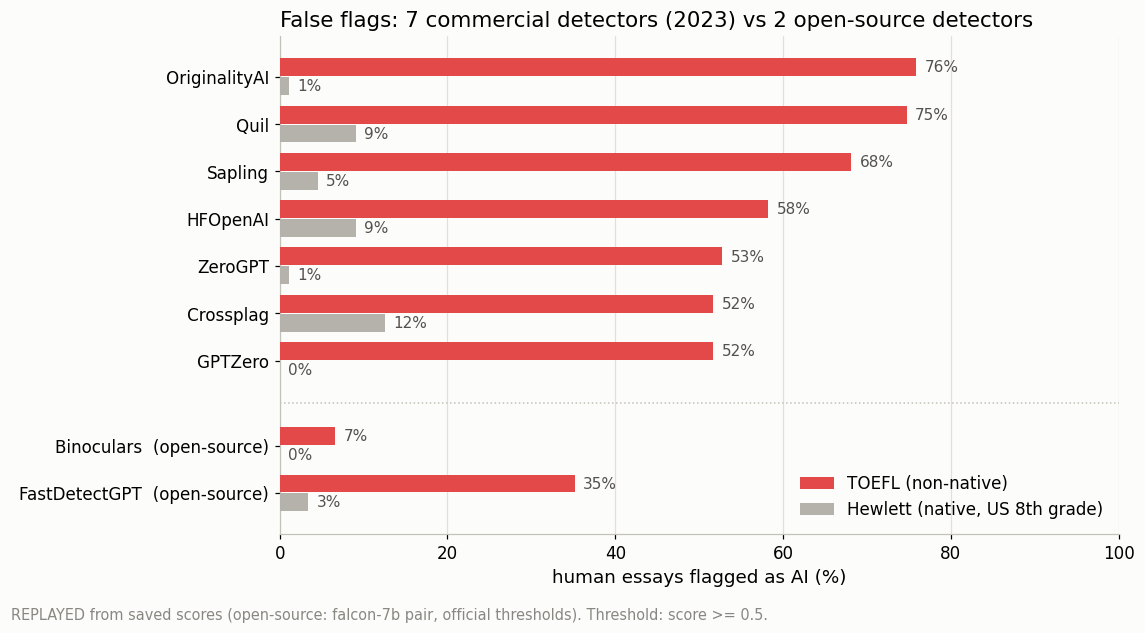

In [5]:
# --- Figure 1: false flags, commercial vs open-source ---
P.setup()
order = list(cm.sort_values("TOEFL_flagged", ascending=False).index) + list(AUDIT[AUDIT.kind.str.startswith("open")].index)
down = np.r_[np.arange(len(cm)), len(cm) + 0.8 + np.arange(len(order) - len(cm))]      # positions from the top; a gap before the open-source detectors
ypos = down.max() - down
fig, ax = plt.subplots(figsize=(10.5, 5.6))
for y, d in zip(ypos, order):
    r = AUDIT.loc[d]
    ax.barh(y + 0.2, r.TOEFL_flagged * 100, height=0.38, color=P.C_TOEFL, zorder=3, label="TOEFL (non-native)" if d == order[0] else None)
    ax.barh(y - 0.2, r.Hewlett_flagged * 100, height=0.38, color=P.GRAY, zorder=3, label="Hewlett (native, US 8th grade)" if d == order[0] else None)
    ax.text(r.TOEFL_flagged * 100 + 1, y + 0.2, f"{r.TOEFL_flagged * 100:.0f}%", va="center", fontsize=10, color=P.INK2)
    ax.text(r.Hewlett_flagged * 100 + 1, y - 0.2, f"{r.Hewlett_flagged * 100:.0f}%", va="center", fontsize=10, color=P.INK2)
ax.set_yticks(ypos); ax.set_yticklabels([d + ("  (open-source)" if d in osd else "") for d in order]); ax.set_xlim(0, 100)
ax.xaxis.grid(True, color=P.GRID); ax.set_axisbelow(True); ax.set_xlabel("human essays flagged as AI (%)")
ax.axhline(ypos[len(cm) - 1] - 0.9, color=P.BASE, linewidth=1, linestyle=":")
ax.legend(frameon=False, loc="lower right"); ax.set_title("False flags: 7 commercial detectors (2023) vs 2 open-source detectors", loc="left")
fig.text(0.01, -0.02, "REPLAYED from saved scores (open-source: falcon-7b pair, official thresholds). Threshold: score >= 0.5.", fontsize=9.5, color=P.MUTED)
fig.tight_layout(); fig.savefig(FIG_DIR / "nb01_fig1_false_flags.png", bbox_inches="tight"); plt.show()

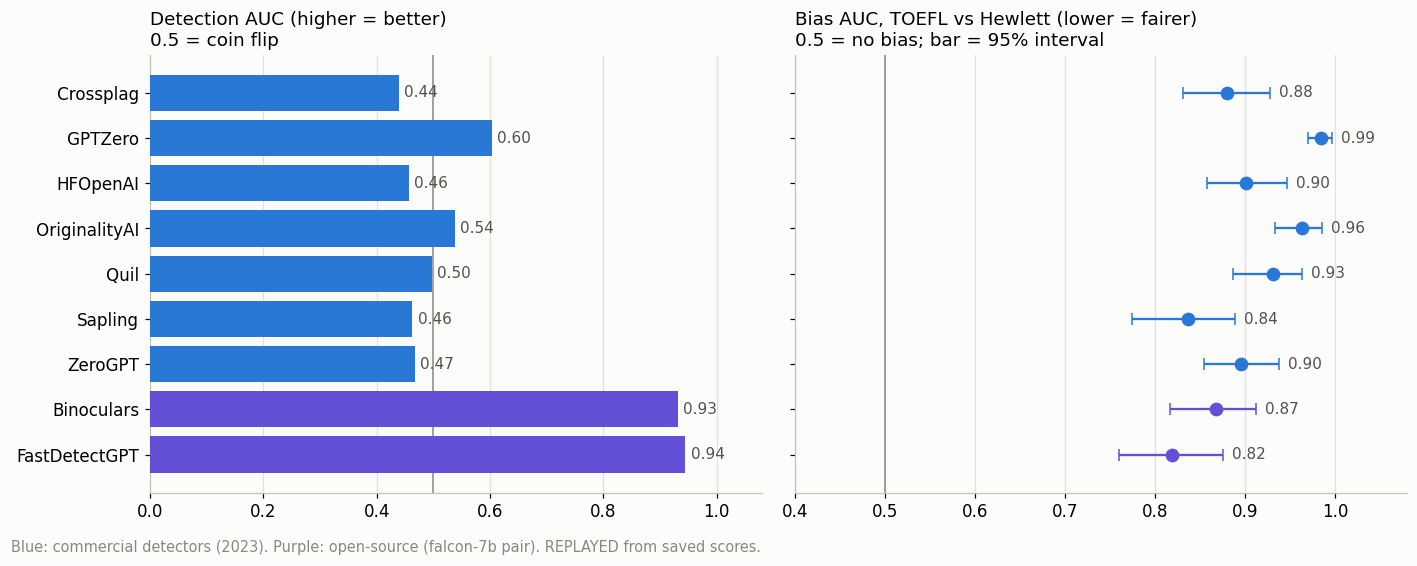

In [6]:
# --- Figure 2: detection AUC (higher is better) and bias AUC (0.5 = no bias) ---
P.setup()
names = list(AUDIT.index)[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
col = [P.C_OS if n in osd else P.C_LR for n in names]
a1.barh(range(len(names)), [AUDIT.loc[n, "detection_AUC"] for n in names], color=col, zorder=3)
for i, n in enumerate(names): a1.text(AUDIT.loc[n, "detection_AUC"] + 0.01, i, f"{AUDIT.loc[n, 'detection_AUC']:.2f}", va="center", fontsize=10, color=P.INK2)
a1.axvline(0.5, color=P.MUTED, linewidth=1); a1.set_xlim(0, 1.08); a1.set_yticks(range(len(names))); a1.set_yticklabels(names)
a1.set_title("Detection AUC (higher = better)\n0.5 = coin flip", loc="left", fontsize=12); a1.xaxis.grid(True, color=P.GRID); a1.set_axisbelow(True)
for i, n in enumerate(names):
    r = AUDIT.loc[n]
    a2.errorbar(r.bias_AUC, i, xerr=[[r.bias_AUC - r.ci_low], [r.ci_high - r.bias_AUC]], fmt="o", color=col[i], markersize=8, capsize=4, zorder=3)
    a2.text(r.ci_high + 0.01, i, f"{r.bias_AUC:.2f}", va="center", fontsize=10, color=P.INK2)
a2.axvline(0.5, color=P.MUTED, linewidth=1); a2.set_xlim(0.4, 1.08)
a2.set_title("Bias AUC, TOEFL vs Hewlett (lower = fairer)\n0.5 = no bias; bar = 95% interval", loc="left", fontsize=12); a2.xaxis.grid(True, color=P.GRID); a2.set_axisbelow(True)
fig.text(0.01, -0.02, "Blue: commercial detectors (2023). Purple: open-source (falcon-7b pair). REPLAYED from saved scores.", fontsize=9.5, color=P.MUTED)
fig.tight_layout(); fig.savefig(FIG_DIR / "nb01_fig2_detection_and_bias_auc.png", bbox_inches="tight"); plt.show()

**Reading the figure.** Every detector has a bias AUC far above 0.5 (0.82 to 0.99): whatever the threshold, a random
non-native essay is much more likely to get an "AI-like" score than a random native essay. The best commercial detector
(Sapling, 0.84) and Fast-DetectGPT (0.82) are close; the intervals overlap. Part 1.3 checks whether essay *length* explains it.

## 1.2 How the saved open-source scores were produced (and a check that the transformation is what we think)
The A40 run stored two numbers per essay: `raw` (the detector's own number) and `score` (a 0-1 number where the official
threshold sits at 0.5). Both transformations are written in `a40/score_opensource.py`. We re-apply them to `raw` and
compare with the stored `score`. For Binoculars (lower raw = more AI-like) the stored score is `1/(1+exp(40*(raw - T)))`
with T the official "low false-positive rate" threshold; we *recover* T from the data instead of assuming it.
For Fast-DetectGPT the raw value is turned into a probability with the two normal curves (human, AI) published with the detector.

In [7]:
from scipy.stats import norm
b, f = osd["Binoculars"], osd["FastDetectGPT"]
ok = (b.score > 1e-6) & (b.score < 1 - 1e-6)                      # rows where the sigmoid is not saturated
T_bino = (b.raw[ok] - np.log(1 / b.score[ok] - 1) / 40)           # solve score = 1/(1+exp(40(raw - T))) for T
T = float(T_bino.median())
bino_diff = float(np.abs(1 / (1 + np.exp(40 * (b.raw - T))) - b.score).max())
FD = dict(mu0=-0.0707, sigma0=0.9520, mu1=2.9306, sigma1=1.9039)  # official falcon-7b / falcon-7b-instruct parameters, as in a40/score_opensource.py
p0, p1 = norm.pdf(f.raw, FD["mu0"], FD["sigma0"]), norm.pdf(f.raw, FD["mu1"], FD["sigma1"])
fd_diff = float(np.abs(p1 / (p0 + p1) - f.score).max())
print(f"Binoculars: official threshold recovered from the saved data T = {T:.4f} (spread over {ok.sum():,} essays: {T_bino.std():.1e}); "
      f"largest |recomputed score - stored score| = {bino_diff:.1e}")
print(f"Fast-DetectGPT: largest |recomputed probability - stored score| = {fd_diff:.1e}")
print("Binoculars: raw below T means 'AI'. Fast-DetectGPT: higher raw (sampling discrepancy) means 'AI'; raw = 0.5 probability point is the official threshold.")

Binoculars: official threshold recovered from the saved data T = 0.8536 (spread over 14,263 essays: 8.7e-15); largest |recomputed score - stored score| = 1.1e-16
Fast-DetectGPT: largest |recomputed probability - stored score| = 1.1e-16
Binoculars: raw below T means 'AI'. Fast-DetectGPT: higher raw (sampling discrepancy) means 'AI'; raw = 0.5 probability point is the official threshold.


## 1.3 Length control: is the bias just about essay length?
TOEFL essays are short (median 104 words) and the Hewlett essays are long (median 378 words), and detectors can behave
differently on short texts. *Length matching* pairs every TOEFL essay only with Hewlett essays whose word count is within
+/-30% of its own, then recomputes the bias AUC on those pairs only (same method as `a40/length_control.py`). Open-source
detectors only, because that is what the original length analysis covers.

In [8]:
wc = exams[["essay_id", "text"]].assign(w=lambda d: d.text.map(lambda s: len(str(s).split())))   # raw word counts, as in a40/length_control.py
def length_control(p):
    d = p.merge(wc[["essay_id", "w"]], on="essay_id")
    t, h = d[d.corpus == M.TOEFL], d[d.corpus == M.HEWLETT]
    tt, hh, partners_t, partners_h = [], [], set(), set()
    for r in t.itertuples():
        m = h[(h.w >= 0.7 * r.w) & (h.w <= 1.3 * r.w)]
        if len(m):
            tt += [r.score] * len(m); hh += list(m.score); partners_t.add(r.essay_id); partners_h |= set(m.essay_id)
    lo, hi = M.auc_ci(tt, hh, n_boot=N_BOOT, rng=np.random.default_rng(0))[1:]
    return dict(bias_all_pairs=M.auc(t.score, h.score), bias_length_matched=M.auc(tt, hh), matched_ci_low=lo, matched_ci_high=hi,
                n_pairs_matched=len(tt), toefl_essays_matched=len(partners_t), hewlett_essays_matched=len(partners_h),
                toefl_words_median=float(t.w.median()), hewlett_words_median=float(h.w.median()))
LC = pd.DataFrame({n: length_control(osd[n]) for n in osd}).T
display(LC.round(3))
for n in LC.index:
    r = LC.loc[n]
    print(f"{n}: bias AUC {r.bias_all_pairs:.2f} (all pairs) -> {r.bias_length_matched:.2f} (length-matched, 95% interval {r.matched_ci_low:.2f}-{r.matched_ci_high:.2f}; "
          f"{int(r.n_pairs_matched)} pairs from {int(r.toefl_essays_matched)} TOEFL and {int(r.hewlett_essays_matched)} Hewlett essays)")

,bias_all_pairs,bias_length_matched,matched_ci_low,matched_ci_high,n_pairs_matched,toefl_essays_matched,hewlett_essays_matched,toefl_words_median,hewlett_words_median
Binoculars,0.868,0.786,0.719,0.839,99.0,63.0,4.0,104.0,378.5
FastDetectGPT,0.819,0.760,0.688,0.819,99.0,63.0,4.0,104.0,378.5


Binoculars: bias AUC 0.87 (all pairs) -> 0.79 (length-matched, 95% interval 0.72-0.84; 99 pairs from 63 TOEFL and 4 Hewlett essays)
FastDetectGPT: bias AUC 0.82 (all pairs) -> 0.76 (length-matched, 95% interval 0.69-0.82; 99 pairs from 63 TOEFL and 4 Hewlett essays)


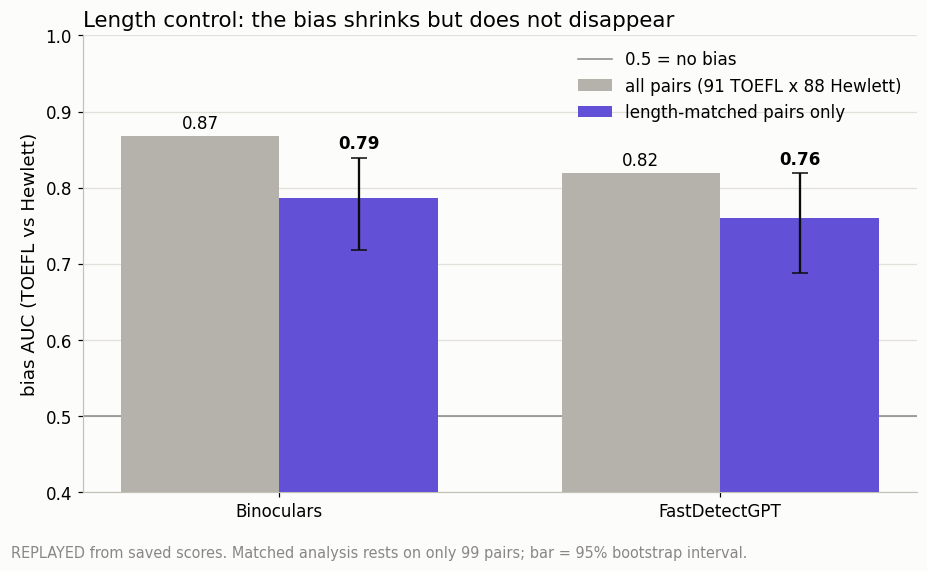

In [9]:
P.setup()
fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(len(LC)); w = 0.36
ax.bar(x - w / 2, LC.bias_all_pairs.astype(float), w, color=P.GRAY, zorder=3, label="all pairs (91 TOEFL x 88 Hewlett)")
ax.bar(x + w / 2, LC.bias_length_matched.astype(float), w, color=P.C_OS, zorder=3, label="length-matched pairs only")
ax.errorbar(x + w / 2, LC.bias_length_matched.astype(float), yerr=[(LC.bias_length_matched - LC.matched_ci_low).astype(float), (LC.matched_ci_high - LC.bias_length_matched).astype(float)],
            fmt="none", color=P.INK, capsize=5, zorder=4)
for i, n in enumerate(LC.index):
    ax.text(i - w / 2, LC.bias_all_pairs.iloc[i] + 0.01, f"{LC.bias_all_pairs.iloc[i]:.2f}", ha="center", fontsize=11)
    ax.text(i + w / 2, LC.matched_ci_high.iloc[i] + 0.012, f"{LC.bias_length_matched.iloc[i]:.2f}", ha="center", fontsize=11, fontweight="bold")
ax.axhline(0.5, color=P.MUTED, linewidth=1, label="0.5 = no bias")
ax.set_xticks(x); ax.set_xticklabels(LC.index); ax.set_ylim(0.4, 1.0); ax.set_ylabel("bias AUC (TOEFL vs Hewlett)")
ax.yaxis.grid(True, color=P.GRID); ax.set_axisbelow(True); ax.legend(frameon=False, loc="upper right")
ax.set_title("Length control: the bias shrinks but does not disappear", loc="left")
fig.text(0.01, -0.03, f"REPLAYED from saved scores. Matched analysis rests on only {int(LC.n_pairs_matched.iloc[0])} pairs; bar = 95% bootstrap interval.", fontsize=9.5, color=P.MUTED)
fig.tight_layout(); fig.savefig(FIG_DIR / "nb01_fig3_length_control.png", bbox_inches="tight"); plt.show()

**Reading the figure.** Matching on length lowers the bias AUC (Binoculars 0.87 to 0.79, Fast-DetectGPT 0.82 to 0.76), so
part of the raw bias comes from length. It stays well above 0.5, so length is not the whole explanation. Caution: the
matched analysis rests on only 99 pairs, and (see the numbers printed above) they come from just a handful of Hewlett
essays, because most Hewlett essays are too long to match a short TOEFL essay; its interval is wide.

## 1.4 Extra check (new, not in the archived tables): the same bias against native essays *without* placeholders
Hewlett essays contain anonymisation tags such as `@CAPS1` (see 1.5), which are odd, hard-to-predict tokens. To see whether the
bias depends on the choice of native comparison set we recompute the bias AUC of TOEFL against the 70 native college essays,
which contain no placeholders. **This is a new number for this notebook; there is no archived value to check it against.**

In [10]:
rows = []
for name, kind, p in DETECTORS:
    by = M.by_corpus(p)
    a, lo, hi = M.auc_ci(by[M.TOEFL], by["CollegeEssay_real_70"], n_boot=N_BOOT, rng=rng)
    rows.append(dict(detector=name, bias_AUC_vs_Hewlett=AUDIT.loc[name, "bias_AUC"], bias_AUC_vs_college=a, college_ci_low=lo, college_ci_high=hi,
                     college_flagged=M.flag_rate(by["CollegeEssay_real_70"])))
EXTRA = pd.DataFrame(rows).set_index("detector"); display(EXTRA.round(3))
print("NEW (not archived, no PASS/FAIL): all nine detectors still rank TOEFL essays above college essays:", bool((EXTRA.bias_AUC_vs_college > 0.5).all()),
      f"(lowest {EXTRA.bias_AUC_vs_college.min():.2f}, highest {EXTRA.bias_AUC_vs_college.max():.2f}).")

,bias_AUC_vs_Hewlett,bias_AUC_vs_college,college_ci_low,college_ci_high,college_flagged
detector,,,,,
Crossplag,0.880,0.976,0.951,0.994,0.000
GPTZero,0.985,0.960,0.923,0.988,0.014
HFOpenAI,0.902,0.973,0.947,0.990,0.000
OriginalityAI,0.963,0.918,0.868,0.952,0.043
Quil,0.931,0.976,0.947,0.994,0.014
Sapling,0.836,0.872,0.810,0.918,0.014
ZeroGPT,0.895,0.877,0.821,0.926,0.029
Binoculars,0.868,0.816,0.751,0.875,0.000
FastDetectGPT,0.819,0.732,0.646,0.805,0.143


NEW (not archived, no PASS/FAIL): all nine detectors still rank TOEFL essays above college essays: True (lowest 0.73, highest 0.98).


## 1.5 The word-predictability analysis: recomputed from the saved per-essay perplexities
*Perplexity* is how surprised a language model is by a text: low perplexity means predictable text. Two numbers from the
project notes are recomputed here from `data/ppl/` (per-essay perplexities written on the A40 server by `a40/all_ppl.py`
and `a40/all_ppl_native.py`; one record per essay with the word count, whether it contains an `@` placeholder, the
falcon-7b perplexity, and GPTZero's own perplexity and score):
* GPTZero's own perplexity: median **42** for the 91 TOEFL essays vs **86** for the 70 native college essays.
* falcon-7b: **89%** of the TOEFL essays are more predictable than the median native essay.

**The 89% depends on which native essays are the yardstick.** It holds against the college essays only. Against the
145 CS224N essays it is 68%. Against Hewlett it is also 89%, but Hewlett must not be used for perplexity comparisons
(85 of its 88 essays carry `@` placeholders, see below), so that agreement means nothing. Both shares are printed
below, together with the medians they use. Note also that the native sets differ in length (college essays are long,
CS224N essays short), which is a further reason not to read the 89% as one universal number.

In [11]:
import re, json
hew = exams[exams.corpus == M.HEWLETT]
n_at, n_caps = int(hew.text.str.contains("@").sum()), int(hew.text.str.contains("@CAPS").sum())
print(f"Hewlett essays: {len(hew)}; containing an '@' placeholder: {n_at}; of which '@CAPS...': {n_caps}.")
print("Examples of the placeholders:", sorted(set(re.findall(r"@[A-Z]+\d*", " ".join(hew.text))))[:12])
for c in ["TOEFL_real_91", "CollegeEssay_real_70", "CS224N_real_145"]:
    print(f"{c}: {int(exams[exams.corpus == c].text.str.contains('@').sum())} essays with '@'")

# saved per-essay perplexities (data/ppl/: all_ppl.json = TOEFL, Hewlett, TOEFL polished; all_ppl_native.json = college, CS224N)
PPL = {**json.load(open("data/ppl/all_ppl.json")), **json.load(open("data/ppl/all_ppl_native.json"))}
PPL_N = {k: len(v) for k, v in PPL.items()}
print("\nRecords in data/ppl/:", PPL_N)
med = lambda corp, key: float(np.median([r[key] for r in PPL[corp]]))
hew_at_ppl = int(sum(r["has_at"] for r in PPL["HewlettStudentEssay_real_88"]))
print(f"Hewlett records flagged has_at in data/ppl/: {hew_at_ppl} of {PPL_N['HewlettStudentEssay_real_88']}")
GZ_T, GZ_C = med("TOEFL_real_91", "gptzero_ppl"), med("CollegeEssay_real_70", "gptzero_ppl")
print(f"\nGPTZero's own perplexity, median: TOEFL {GZ_T:.2f} vs native college essays {GZ_C:.2f}")
SHARE = {}
tf = np.array([r["falcon_ppl"] for r in PPL["TOEFL_real_91"]])
for name, corp, usable in (("college", "CollegeEssay_real_70", "usable yardstick"), ("CS224N", "CS224N_real_145", "usable yardstick"),
                           ("Hewlett", "HewlettStudentEssay_real_88", "DO NOT USE: @ placeholders")):
    m_ = med(corp, "falcon_ppl"); k = int((tf < m_).sum())
    SHARE[name] = dict(median=m_, k=k, share=k / len(tf))
    print(f"falcon-7b: share of the 91 TOEFL essays more predictable than the median {name} essay (median perplexity {m_:.2f}): "
          f"{k / len(tf):.4f} ({k}/{len(tf)})   [{usable}]")
print("\nThe 89% claim holds against the college essays only (0.89), not against CS224N (0.68).")

Hewlett essays: 88; containing an '@' placeholder: 85; of which '@CAPS...': 72.
Examples of the placeholders: ['@CAPS1', '@CAPS10', '@CAPS11', '@CAPS12', '@CAPS13', '@CAPS14', '@CAPS15', '@CAPS2', '@CAPS3', '@CAPS4', '@CAPS5', '@CAPS6']
TOEFL_real_91: 0 essays with '@'
CollegeEssay_real_70: 0 essays with '@'
CS224N_real_145: 0 essays with '@'

Records in data/ppl/: {'TOEFL_real_91': 91, 'HewlettStudentEssay_real_88': 88, 'TOEFL_gpt4polished_91': 91, 'CollegeEssay_real_70': 70, 'CS224N_real_145': 145}
Hewlett records flagged has_at in data/ppl/: 85 of 88

GPTZero's own perplexity, median: TOEFL 42.17 vs native college essays 86.39
falcon-7b: share of the 91 TOEFL essays more predictable than the median college essay (median perplexity 14.63): 0.8901 (81/91)   [usable yardstick]
falcon-7b: share of the 91 TOEFL essays more predictable than the median CS224N essay (median perplexity 12.26): 0.6813 (62/91)   [usable yardstick]
falcon-7b: share of the 91 TOEFL essays more predictable than t

In [12]:
# --- 1.6 All replay checks in one place ------------------------------------------------------------
CHK = []
def add(check, got, archived, tol=1e-9, quoted=None, quoted_tol=None, note=""):
    # PASS = recomputed equals archived (within tol) and, if a rounded quoted value is given, archived agrees with it.
    ok = (not np.isnan(got)) and abs(got - archived) <= tol
    if quoted is not None:
        ok = ok and abs(archived - quoted) <= quoted_tol
    CHK.append(dict(check=check, recomputed=got, archived=archived, quoted=quoted, result="PASS" if ok else "FAIL", note=note))

ar = A_RUNS[A_RUNS.model.isin(["commercial", "Binoculars", "FastDetectGPT"])].set_index("detector")
ap = A_PRF[A_PRF.model.isin(["commercial", "Binoculars", "FastDetectGPT"])].set_index("run")
a_com = ar.loc[M.COMMERCIAL]

# (a) every detector, every column, against the archived tables (largest difference over the 9 detectors)
mine = AUDIT.reset_index()
old = ar[["rate_t05_TOEFL_real_91", "rate_t05_HewlettStudentEssay_real_88", "bias_TOEFL_vs_Hewlett", "det_AI352_vs_LiangHuman2"]].reset_index()
old.columns = ["detector", "TOEFL_flagged", "Hewlett_flagged", "bias_AUC", "detection_AUC"]
old = old.merge(ap.reset_index()[["run", "precision", "recall", "f1", "n_human"]].rename(columns={"run": "detector", "f1": "F1", "n_human": "n_human_scored"}), on="detector")
cmp_a = M.compare_frames(mine, old, ["TOEFL_flagged", "Hewlett_flagged", "bias_AUC", "detection_AUC", "precision", "recall", "F1", "n_human_scored"], "detector", tol=1e-9)
for r in cmp_a.itertuples():
    CHK.append(dict(check=f"all 9 detectors, column {r.column} vs data/results (max difference {r.max_abs_diff:.1e}, {r.rows_compared} rows)",
                    recomputed=np.nan, archived=np.nan, quoted=None, result=r.result, note=""))
# (b) headline numbers: recomputed vs archived table vs the rounded value quoted in our slides
add("commercial: lowest TOEFL flag rate (quoted 52%)", cm.TOEFL_flagged.min(), a_com.rate_t05_TOEFL_real_91.min(), quoted=0.52, quoted_tol=0.005)
add("commercial: highest TOEFL flag rate (quoted 76%)", cm.TOEFL_flagged.max(), a_com.rate_t05_TOEFL_real_91.max(), quoted=0.76, quoted_tol=0.005)
add("commercial: lowest Hewlett flag rate (quoted 0%)", cm.Hewlett_flagged.min(), a_com.rate_t05_HewlettStudentEssay_real_88.min(), quoted=0.0, quoted_tol=0.005)
add("commercial: highest Hewlett flag rate (quoted 12%)", cm.Hewlett_flagged.max(), a_com.rate_t05_HewlettStudentEssay_real_88.max(), quoted=0.12, quoted_tol=0.006,
    note="exact value is 12.5% (Crossplag); '12%' is a rounding down")
add("commercial: lowest detection AUC (quoted 0.44)", cm.detection_AUC.min(), a_com.det_AI352_vs_LiangHuman2.min(), quoted=0.44, quoted_tol=0.005)
add("commercial: highest detection AUC (quoted 0.60)", cm.detection_AUC.max(), a_com.det_AI352_vs_LiangHuman2.max(), quoted=0.60, quoted_tol=0.005)
add("Liang 2023 scores, mean over 7 detectors: TOEFL flagged (quoted 61.9%)", cm.TOEFL_flagged.mean(), a_com.rate_t05_TOEFL_real_91.mean(), quoted=0.619, quoted_tol=0.0005)
add("Liang 2023 scores, mean over 7 detectors: native Hewlett flagged (quoted 5.4%)", cm.Hewlett_flagged.mean(), a_com.rate_t05_HewlettStudentEssay_real_88.mean(), quoted=0.054, quoted_tol=0.0005)
add("best commercial bias AUC = lowest of 7 (quoted 0.84)", cm.bias_AUC.min(), a_com.bias_TOEFL_vs_Hewlett.min(), quoted=0.84, quoted_tol=0.005, note=f"{cm.bias_AUC.idxmin()}")
for n, q in (("Binoculars", dict(fp=0.07, f1=0.82, prec=0.98, rec=0.71, det=0.93, bias=0.87)),
             ("FastDetectGPT", dict(fp=0.35, f1=0.87, prec=None, rec=None, det=0.94, bias=0.82))):
    r, o, pr = AUDIT.loc[n], ar.loc[n], ap.loc[n]
    add(f"{n}: TOEFL false flags (quoted {q['fp']:.0%})", r.TOEFL_flagged, o.rate_t05_TOEFL_real_91, quoted=q["fp"], quoted_tol=0.005)
    add(f"{n}: F1 (quoted {q['f1']:.2f})", r.F1, pr.f1, quoted=q["f1"], quoted_tol=0.005)
    if q["prec"]:
        add(f"{n}: precision (quoted {q['prec']:.2f})", r.precision, pr.precision, quoted=q["prec"], quoted_tol=0.005)
        add(f"{n}: recall (quoted {q['rec']:.2f})", r.recall, pr.recall, quoted=q["rec"], quoted_tol=0.005)
    add(f"{n}: detection AUC (quoted {q['det']:.2f})", r.detection_AUC, o.det_AI352_vs_LiangHuman2, quoted=q["det"], quoted_tol=0.005)
    add(f"{n}: bias AUC (quoted {q['bias']:.2f})", r.bias_AUC, o.bias_TOEFL_vs_Hewlett, quoted=q["bias"], quoted_tol=0.005)
# (c) length control against data/results/length_control.csv
al = A_LEN.set_index("model")
for n, (qa, qm) in (("Binoculars", (0.87, 0.79)), ("FastDetectGPT", (0.82, 0.76))):
    add(f"{n}: bias AUC, all pairs (quoted {qa:.2f})", LC.loc[n, "bias_all_pairs"], al.loc[n, "bias_all_pairs"], quoted=qa, quoted_tol=0.005)
    add(f"{n}: bias AUC, length-matched (quoted {qm:.2f})", LC.loc[n, "bias_length_matched"], al.loc[n, "bias_length_matched"], quoted=qm, quoted_tol=0.005)
    add(f"{n}: number of matched pairs", float(LC.loc[n, "n_pairs_matched"]), float(al.loc[n, "n_pairs_matched"]))
# (d) the score transformations of 1.2
add("Binoculars: stored score = sigmoid of raw with the recovered official threshold (max difference)", bino_diff, 0.0, tol=1e-9)
add("Fast-DetectGPT: stored score = probability from the official normal curves (max difference)", fd_diff, 0.0, tol=1e-9)
# (e) claims about the data itself
add("Hewlett essays containing '@' placeholders (project notes: 85 of 88)", float(n_at), 85.0, tol=0)
add("data/ppl: Hewlett records with has_at (same 85)", float(hew_at_ppl), 85.0, tol=0)
# (f) word predictability, from data/ppl/ (the quoted values are the rounded ones in the project notes)
add("GPTZero median perplexity, TOEFL 42.17 (quoted 42)", GZ_T, 42.17, tol=0.005, quoted=42, quoted_tol=0.5)
add("GPTZero median perplexity, native college essays 86.39 (quoted 86)", GZ_C, 86.39, tol=0.005, quoted=86, quoted_tol=0.5)
add("falcon-7b: median perplexity of college essays", SHARE["college"]["median"], 14.63, tol=0.005)
add("falcon-7b: TOEFL essays below the college median, share (quoted 89%)", SHARE["college"]["share"], 0.8901, tol=0.00005, quoted=0.89, quoted_tol=0.005, note="81 of 91")
add("falcon-7b: TOEFL essays below the college median, count", float(SHARE["college"]["k"]), 81.0, tol=0)
add("falcon-7b: median perplexity of CS224N essays", SHARE["CS224N"]["median"], 12.26, tol=0.005)
add("falcon-7b: TOEFL essays below the CS224N median, share (the 89% does NOT hold here)", SHARE["CS224N"]["share"], 0.6813, tol=0.00005, note="62 of 91")
add("falcon-7b: TOEFL essays below the CS224N median, count", float(SHARE["CS224N"]["k"]), 62.0, tol=0)
add("falcon-7b: TOEFL below the Hewlett median, share (also 0.89, but Hewlett must not be used)", SHARE["Hewlett"]["share"], 0.8901, tol=0.00005, note="81 of 91; @ placeholders")
CHK = pd.DataFrame(CHK)
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 120):
    display(CHK[["check", "recomputed", "archived", "quoted", "result", "note"]].round(4))
for r in CHK.itertuples():
    if np.isnan(r.recomputed):
        print(f"{r.result}  {r.check}")
    else:
        print(f"{r.result}  {r.check}: recomputed {r.recomputed:.4f} vs archived {r.archived:.4f}" + (f" (quoted {r.quoted})" if pd.notna(r.quoted) else "") + (f"  [{r.note}]" if r.note else ""))
N_PASS1, N_FAIL1 = int((CHK.result == "PASS").sum()), int((CHK.result == "FAIL").sum())
print(f"\nREPLAY CHECK SUMMARY: {N_PASS1} PASS, {N_FAIL1} FAIL. All numbers REPLAYED from saved scores; no detector was run in Part 1.")

,check,recomputed,archived,quoted,result,note
0,"all 9 detectors, column TOEFL_flagged vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
1,"all 9 detectors, column Hewlett_flagged vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
2,"all 9 detectors, column bias_AUC vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
3,"all 9 detectors, column detection_AUC vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
4,"all 9 detectors, column precision vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
5,"all 9 detectors, column recall vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
6,"all 9 detectors, column F1 vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
7,"all 9 detectors, column n_human_scored vs data/results (max difference 0.0e+00, 9 rows)",NaN,NaN,NaN,PASS,
8,commercial: lowest TOEFL flag rate (quoted 52%),0.5165,0.5165,0.520,PASS,
9,commercial: highest TOEFL flag rate (quoted 76%),0.7582,0.7582,0.760,PASS,


PASS  all 9 detectors, column TOEFL_flagged vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column Hewlett_flagged vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column bias_AUC vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column detection_AUC vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column precision vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column recall vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column F1 vs data/results (max difference 0.0e+00, 9 rows)
PASS  all 9 detectors, column n_human_scored vs data/results (max difference 0.0e+00, 9 rows)
PASS  commercial: lowest TOEFL flag rate (quoted 52%): recomputed 0.5165 vs archived 0.5165 (quoted 0.52)
PASS  commercial: highest TOEFL flag rate (quoted 76%): recomputed 0.7582 vs archived 0.7582 (quoted 0.76)
PASS  commercial: lowest Hewlett flag rate (quoted 0%): recomputed 

# Part 2 · EXPLAINER and LIVE DEMO: how Binoculars and Fast-DetectGPT work

Both detectors need **no training on human and AI examples** ("zero-shot"). They only ask a language model how *predictable*
an essay is, and call text AI-written when it is too predictable. We write both formulas out below in plain code.

> **Credit.** The two methods are due to others; we implemented the formulas ourselves from the papers (no code copied).
> * **Binoculars:** Abhimanyu Hans et al., *"Spotting LLMs With Binoculars: Zero-Shot Detection of Machine-Generated
>   Text"*, ICML 2024. Official code: <https://github.com/ahans30/Binoculars>.
> * **Fast-DetectGPT:** Guangsheng Bao et al., *"Fast-DetectGPT: Efficient Zero-Shot Detection of Machine-Generated Text
>   via Conditional Probability Curvature"*, ICLR 2024. Official code: <https://github.com/baoguangsheng/fast-detect-gpt>.
>
> The archived scores in Part 1 were made with the *official* code and the official falcon-7b model pair; see
> `a40/score_opensource.py`.

## 2.1 The two ideas in plain words
Take an essay and, for every position, ask a language model: *"given the words so far, how likely is each possible next word?"*
Language models write by choosing likely words, so text that a model finds very predictable is suspicious.
Raw predictability alone is a poor detector, because a short, simple, common-word text is predictable even when a person wrote it.
Both methods therefore **compare the essay's predictability with a yardstick**.

**Binoculars** uses two sibling models that share a vocabulary: an *observer* (a base model) and a *performer*
(its instruction-tuned sibling; the archived run used falcon-7b and falcon-7b-instruct).

* top: the performer's **log-perplexity** of the essay = how surprised the performer is by the words that really came next;
* bottom: the **log cross-perplexity** = how surprised the performer is by the words the *observer* expected;
  it is a yardstick for "how hard is a text in this context for two models that mostly agree";
* $B = \dfrac{\log \mathrm{PPL}_{\text{performer}}(s)}{\log \text{X-PPL}_{\text{observer},\text{performer}}(s)}$ with
  $\log\mathrm{PPL}_2(s) = -\frac1L\sum_i \log p_2(s_i\mid s_{<i})$ and
  $\log\text{X-PPL}_{1,2}(s) = -\frac1L\sum_i\sum_v p_1(v\mid s_{<i})\,\log p_2(v\mid s_{<i})$.
* **A low B means "more predictable than expected": more AI-like.** The official falcon-7b threshold (low false-positive mode) is the value recovered in 1.2.

**Fast-DetectGPT** asks: *is the essay's word choice more probable than the alternatives the model itself would have picked
at each position?*  With a *sampling* model $q$ (imagines alternative words) and a *scoring* model $p$:
$d(s) = \dfrac{\log p(s) - \tilde\mu}{\tilde\sigma}$, where $\tilde\mu=\sum_i\sum_v q(v\mid s_{<i})\log p(v\mid s_{<i})$ is
the log-probability an *average alternative text* would get and
$\tilde\sigma^2=\sum_i\big[\sum_v q\,(\log p)^2-(\sum_v q\log p)^2\big]$ its variance. "Analytic" means we compute $\tilde\mu$ and $\tilde\sigma$ in
closed form over the whole vocabulary instead of drawing many sample texts. **A high $d$ means the essay is unusually probable: more AI-like.**
In the archived run the sampling model was falcon-7b and the scoring model falcon-7b-instruct, so below the *observer* plays the
sampling role and the *performer* the scoring role.

In [13]:
import torch, torch.nn.functional as F

def binoculars_score(observer_logits, performer_logits, labels):
    # Binoculars: log-perplexity of the performer divided by the log cross-perplexity of observer and performer.
    # observer_logits, performer_logits: [L, vocab] raw model outputs for the L next words; labels: [L] the words that really came next.
    # LOW score = text more predictable than the two models' disagreement would suggest = more AI-like.
    perf_logp = F.log_softmax(performer_logits, dim=-1)           # performer: log-probability of every possible next word
    obs_p = F.softmax(observer_logits, dim=-1)                    # observer: probability of every possible next word
    log_ppl = -perf_logp.gather(1, labels[:, None]).mean()        # how surprised the performer is by the REAL next words
    log_xppl = -(obs_p * perf_logp).sum(dim=-1).mean()            # how surprised the performer is by what the OBSERVER expected
    return (log_ppl / log_xppl).item()

def fastdetect_criterion(sampling_logits, scoring_logits, labels):
    # Fast-DetectGPT, analytic sampling discrepancy: (log p(essay) - mean) / std, where mean and std describe the log-probability
    # of an 'average alternative essay' whose words are drawn one by one from the sampling model.
    # HIGH score = essay is unusually probable = more AI-like.
    logp = F.log_softmax(scoring_logits, dim=-1)                  # scoring model: log-probability of every possible next word
    q = F.softmax(sampling_logits, dim=-1)                        # sampling model: probability of every possible next word
    loglik = logp.gather(1, labels[:, None]).sum()                # log-probability of the essay we are testing
    mean_i = (q * logp).sum(dim=-1)                               # per position: expected log-prob of an alternative word
    var_i = (q * logp ** 2).sum(dim=-1) - mean_i ** 2             # per position: variance of that log-prob
    return ((loglik - mean_i.sum()) / var_i.sum().sqrt()).item()

## 2.2 Do the formulas do what the papers say? (self-checks, run in every mode, seconds)
We cannot compare with the official code here, so we test the implementations against their definitions on made-up
model outputs: (a) the vectorised Binoculars code equals a slow loop written straight from the formula; (b) the analytic
mean and variance of Fast-DetectGPT equal what you get by actually sampling 200,000 alternative texts; (c) text sampled from the
model itself gets a Fast-DetectGPT value of mean 0 and standard deviation 1, by construction; (d) text sampled from the model
gets B close to 1, while the model's own *most likely* words (very predictable text) get a clearly lower B, the "looks AI" direction.

In [14]:
torch.manual_seed(0)
L, V = 6, 30
lo, lp = torch.randn(L, V) * 2, torch.randn(L, V) * 2                  # made-up logits of two models
lab = torch.randint(0, V, (L,))
SELF = []
# (a) Binoculars: slow double loop straight from the formula
ppl_sum = x_sum = 0.0
for i in range(L):
    po, lpp = torch.softmax(lo[i], 0), torch.log_softmax(lp[i], 0)
    ppl_sum += -lpp[lab[i]].item()
    x_sum += -sum(po[v].item() * lpp[v].item() for v in range(V))
SELF.append(("(a) Binoculars: vectorised code equals the slow loop", abs((ppl_sum / L) / (x_sum / L) - binoculars_score(lo, lp, lab)) < 1e-5))
# (b) Fast-DetectGPT: analytic mean / variance vs Monte Carlo over 200,000 alternative texts
K = 200_000
q, logp = torch.softmax(lo, -1), torch.log_softmax(lp, -1)
draws = torch.multinomial(q, K, replacement=True)                       # [L, K]: alternative words drawn from the sampling model
alt = torch.gather(logp, 1, draws).sum(0)                               # [K]: log-probability of each alternative text
an_mean = (q * logp).sum().item(); an_var = ((q * logp ** 2).sum(-1) - (q * logp).sum(-1) ** 2).sum().item()
SELF.append(("(b1) Fast-DetectGPT: analytic mean = Monte-Carlo mean (within 4 standard errors)", abs(alt.mean().item() - an_mean) < 4 * (alt.var().item() / K) ** 0.5))
SELF.append(("(b2) Fast-DetectGPT: analytic variance = Monte-Carlo variance (within 3%)", abs(alt.var().item() / an_var - 1) < 0.03))
# (c) text sampled from the model: criterion has mean 0 and sd 1 (sampling model = scoring model = lp)
crit = [fastdetect_criterion(lp, lp, torch.multinomial(torch.softmax(lp, -1), 1)[:, 0]) for _ in range(3000)]
SELF.append(("(c) Fast-DetectGPT: model-sampled text has mean about 0 and sd about 1", abs(np.mean(crit)) < 0.1 and abs(np.std(crit) - 1) < 0.1))
# (d) Binoculars: sampled text ~ 1, most-likely-word text lower (more AI-like)
L2 = 400; l2 = torch.randn(L2, V) * 2
b_sampled = binoculars_score(l2, l2, torch.multinomial(torch.softmax(l2, -1), 1)[:, 0])
b_greedy = binoculars_score(l2, l2, l2.argmax(-1))
SELF.append((f"(d) Binoculars: sampled text B={b_sampled:.2f} (about 1); most-likely-words text B={b_greedy:.2f} is lower", abs(b_sampled - 1) < 0.15 and b_greedy < b_sampled - 0.2))
for name, ok in SELF:
    print("PASS " if ok else "FAIL ", name)
N_PASS2, N_FAIL2 = sum(ok for _, ok in SELF), sum(not ok for _, ok in SELF)
print(f"SELF-CHECK SUMMARY: {N_PASS2} PASS, {N_FAIL2} FAIL")

PASS  (a) Binoculars: vectorised code equals the slow loop
PASS  (b1) Fast-DetectGPT: analytic mean = Monte-Carlo mean (within 4 standard errors)
PASS  (b2) Fast-DetectGPT: analytic variance = Monte-Carlo variance (within 3%)
PASS  (c) Fast-DetectGPT: model-sampled text has mean about 0 and sd about 1
PASS  (d) Binoculars: sampled text B=0.99 (about 1); most-likely-words text B=0.50 is lower
SELF-CHECK SUMMARY: 5 PASS, 0 FAIL


## 2.3 LIVE with STAND-IN small models

> **LIVE - STAND-IN small models, not comparable to the archived falcon-7b scores.**
> The real detectors use two 7-billion-parameter models (about 28 GB). Here the same formulas run on two tiny models that
> share a tokenizer (SMOKE: `gpt2` + `distilgpt2`; FAST/FULL: `Qwen2.5-0.5B` + `Qwen2.5-0.5B-Instruct`). Small models see
> language differently, and the official thresholds belong to falcon-7b, so we **do not use them**. Every live number below is
> a demonstration of the mechanism on a small sample, not a measurement of the detectors. Archived values appear only as labelled context.

The sample is drawn at random (fixed seed) from the Liang et al. essays: TOEFL essays (non-native, human), native college
essays (human; Hewlett is not used because of its `@CAPS` placeholders), GPT-3 essays (AI). Essays are cut at 512 tokens, as in the archived run.

In [15]:
from ddlib import zeroshot as Z
device = Z.pick_device()
if device == "cpu" and LIVE["pair"][0].startswith("Qwen") and not os.environ.get("DD_LIVE_PAIR"):
    # In our CPU test the Qwen pair needed about 40 s per essay, so on a runtime without a GPU we use the gpt2 pair instead.
    LIVE = dict(LIVE, pair=("gpt2", "distilgpt2"))
    print("No GPU found: using the gpt2 + distilgpt2 stand-in pair (the Qwen pair is far too slow on a CPU). Switch the runtime to a GPU for the Qwen pair.")
OBS, PERF = LIVE["pair"]
STANDIN = f"STAND-IN small models ({OBS} + {PERF}), not comparable to the archived falcon-7b scores"
print("=" * 100); print("PART 2 LIVE - " + STANDIN); print("=" * 100)
dtype = LIVE_DTYPE or ("float16" if device == "cuda" else "float32")
print(f"device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else "") + f" | weights dtype: {dtype}")
sample = Z.pick_sample(exams, *LIVE["sample"], seed=0)
sample["text"] = sample.text.map(clean)                      # same cleaning as the archived run
GT, GN, GA = "TOEFL (non-native, human)", "college (native, human)", "GPT-3 (AI)"
print(sample.group.value_counts().to_string(), f"\nessays in total: {len(sample)}")

def score_essays(tok, m_obs, m_perf, texts, dev, every=25):
    # the two scores plus the observer's perplexity for each essay
    rows, t = [], time.time()
    for i, text in enumerate(texts):
        ids = Z.encode(tok, text, dev)
        lo_, lp_ = Z.next_word_logits(m_obs, ids), Z.next_word_logits(m_perf, ids)   # [L-1, vocab]
        lab_ = ids[0, 1:]
        rows.append(dict(tokens=int(ids.shape[1]), binoculars=binoculars_score(lo_, lp_, lab_),
                         fastdetect=fastdetect_criterion(lo_, lp_, lab_), observer_ppl=float(torch.exp(F.cross_entropy(lo_, lab_)))))
        if (i + 1) % every == 0 and len(texts) > every:
            print(f"  {i + 1}/{len(texts)} essays, {time.time() - t:.0f} s")
    return pd.DataFrame(rows)

def run_live(dt):
    t = time.time(); tok, m_obs, m_perf = Z.load_pair(OBS, PERF, device, dt); t_load = time.time() - t
    t = time.time(); res = score_essays(tok, m_obs, m_perf, sample.text.tolist(), device)
    return tok, m_obs, m_perf, res, t_load, time.time() - t
try:
    tok, m_obs, m_perf, res, t_load, t_score = run_live(dtype)
except RuntimeError as e:
    if "non-finite" not in str(e) or dtype == "float32":
        raise
    print("float16 gave non-finite values; repeating in float32:", e)
    dtype = "float32"; tok, m_obs, m_perf, res, t_load, t_score = run_live(dtype)
live = pd.concat([sample.drop(columns="text"), res], axis=1)
print(f"\nLoaded the two models in {t_load:.0f} s (mostly download on the first run); scored {len(live)} essays in {t_score:.0f} s on {device} ({dtype}). "
      "These are wall-clock times of THIS run on THIS machine.")
display(live.drop(columns="corpus").head(12).round(3))

No GPU found: using the gpt2 + distilgpt2 stand-in pair (the Qwen pair is far too slow on a CPU). Switch the runtime to a GPU for the Qwen pair.
PART 2 LIVE - STAND-IN small models (gpt2 + distilgpt2), not comparable to the archived falcon-7b scores
device: cpu | weights dtype: float32
group
TOEFL (non-native, human)    91
college (native, human)      70
GPT-3 (AI)                   39 
essays in total: 200


loading gpt2 (float32, cpu); the first time this downloads the weights, which can take a few minutes ...


W1118 16:35:48.080000 26464 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


loading distilgpt2 (float32, cpu); the first time this downloads the weights, which can take a few minutes ...


  25/200 essays, 4 s


  50/200 essays, 7 s


... (3 outputs left out)

  150/200 essays, 34 s


  175/200 essays, 38 s


  200/200 essays, 41 s

Loaded the two models in 6 s (mostly download on the first run); scored 200 essays in 41 s on cpu (float32). These are wall-clock times of THIS run on THIS machine.


,essay_id,group,tokens,binoculars,fastdetect,observer_ppl
0,TOEFL_real_91#2,"TOEFL (non-native, human)",136,0.885,1.893,17.690
1,TOEFL_real_91#13,"TOEFL (non-native, human)",103,0.957,0.695,35.563
2,TOEFL_real_91#53,"TOEFL (non-native, human)",164,0.955,0.802,21.957
3,TOEFL_real_91#41,"TOEFL (non-native, human)",108,1.030,-0.448,34.267
4,TOEFL_real_91#86,"TOEFL (non-native, human)",114,0.951,0.712,17.737
5,TOEFL_real_91#30,"TOEFL (non-native, human)",126,0.752,3.751,9.254
6,TOEFL_real_91#45,"TOEFL (non-native, human)",124,1.008,-0.134,29.771
7,TOEFL_real_91#43,"TOEFL (non-native, human)",151,0.907,1.663,19.772
8,TOEFL_real_91#59,"TOEFL (non-native, human)",112,0.993,0.108,33.691
9,TOEFL_real_91#90,"TOEFL (non-native, human)",124,0.948,0.841,27.774


In [16]:
# AI-likeness: bigger = more AI-like for both detectors (Binoculars is flipped because LOW B means AI)
def ai_like(df, col): return -df[col] if col == "binoculars" else df[col]

def small_audit(df, s):
    # df: has 'group'; s: AI-likeness per essay (same index). Illustrative cut-off = flags 90% of the AI essays IN THIS SAMPLE.
    t, n, a = s[df.group == GT], s[df.group == GN], s[df.group == GA]
    cut = np.quantile(a, 0.10)
    return {"detection AUC": M.auc(a, pd.concat([t, n])), "bias AUC (TOEFL vs college)": M.auc(t, n),
            "TOEFL flagged": (t >= cut).mean(), "college flagged": (n >= cut).mean()}

arch_same = {k: live[["essay_id", "group"]].merge(osd[k][["essay_id", "raw"]], on="essay_id") for k in osd}   # archived falcon-7b raw scores of the SAME essays
names = {"binoculars": "Binoculars", "fastdetect": "FastDetectGPT"}
rows = {}
for col, name in names.items():
    live_m = small_audit(live, ai_like(live, col))
    a = arch_same[name]; arch_m = small_audit(a, -a.raw if col == "binoculars" else a.raw)
    full = AUDIT.loc[name]
    rows[name] = {**{("LIVE stand-in (this run, this sample)", k): v for k, v in live_m.items()},
                  **{("ARCHIVED falcon-7b, same essays, same 90% cut-off (context only)", k): v for k, v in arch_m.items()},
                  **{("ARCHIVED falcon-7b, all 91 TOEFL + 88 Hewlett, official threshold (context only)", k): v
                     for k, v in {"TOEFL flagged": full.TOEFL_flagged, "bias AUC (TOEFL vs Hewlett)": full.bias_AUC, "detection AUC": full.detection_AUC}.items()}}
side = pd.DataFrame(rows).T
print("LIVE numbers are from the " + STANDIN + ".")
print(f"Sample: {(live.group == GT).sum()} TOEFL, {(live.group == GN).sum()} college, {(live.group == GA).sum()} AI essays. The illustrative cut-off is fitted on this same sample "
      "(it flags 90% of its AI essays), so flag rates are optimistic and only show the idea of a false flag; the official thresholds are not used.")
display(side.round(2))
for col, name in names.items():
    a = arch_same[name]
    rho = live[col].corr(a.raw.reset_index(drop=True), method="spearman")
    print(f"{name}: Spearman rank agreement of the stand-in score with the archived falcon-7b score on these {len(live)} essays: {rho:.2f} (descriptive)")
print("A stand-in can disagree with falcon-7b (low rank agreement above, or a bias AUC near 0.5 or below). That says something about the small models, not about the archived audit of Part 1.")

LIVE numbers are from the STAND-IN small models (gpt2 + distilgpt2), not comparable to the archived falcon-7b scores.
Sample: 91 TOEFL, 70 college, 39 AI essays. The illustrative cut-off is fitted on this same sample (it flags 90% of its AI essays), so flag rates are optimistic and only show the idea of a false flag; the official thresholds are not used.


LIVE stand-in (this run, this sample)                                                            \
                                      detection AUC bias AUC (TOEFL vs college) TOEFL flagged college flagged   
Binoculars                                     0.72                        0.71          0.77            0.57   
FastDetectGPT                                  0.68                        0.44          0.77            0.77   

              ARCHIVED falcon-7b, same essays, same 90% cut-off (context only)                                                            \
                                                                 detection AUC bias AUC (TOEFL vs college) TOEFL flagged college flagged   
Binoculars                                                  0.95                                      0.82          0.24            0.00   
FastDetectGPT                                               0.96                                      0.73          0.07            0.07   

              ARCHIVED falcon-7b, all 91 TOEFL + 88 Hewlett, official threshold (context only)                                            
                                                                                 TOEFL flagged bias AUC (TOEFL vs Hewlett) detection AUC  
Binoculars                                                  0.07                                                      0.87          0.93  
FastDetectGPT                                               0.35                                                      0.82          0.94

Binoculars: Spearman rank agreement of the stand-in score with the archived falcon-7b score on these 200 essays: 0.74 (descriptive)
FastDetectGPT: Spearman rank agreement of the stand-in score with the archived falcon-7b score on these 200 essays: 0.58 (descriptive)
A stand-in can disagree with falcon-7b (low rank agreement above, or a bias AUC near 0.5 or below). That says something about the small models, not about the archived audit of Part 1.


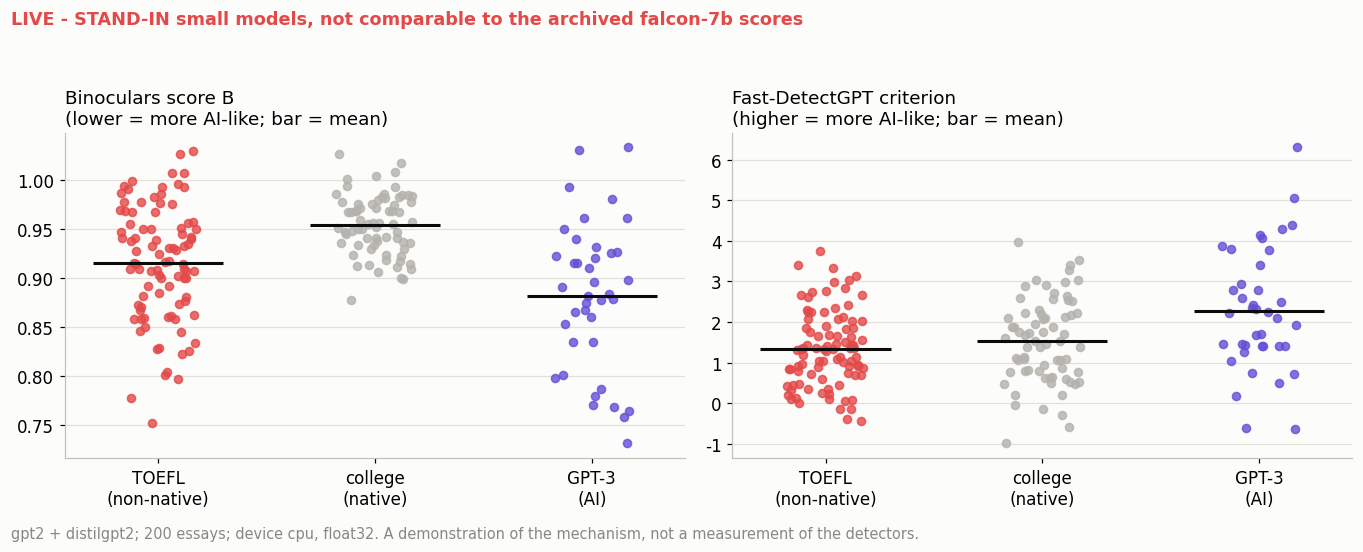

In [17]:
P.setup()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
cols_g = {GT: P.C_TOEFL, GN: P.GRAY, GA: P.C_OS}
for ax, (col, title, note) in zip(axes, [("binoculars", "Binoculars score B", "lower = more AI-like"), ("fastdetect", "Fast-DetectGPT criterion", "higher = more AI-like")]):
    for i, g in enumerate([GT, GN, GA]):
        v = live.loc[live.group == g, col].to_numpy()
        jit = np.random.default_rng(1).uniform(-0.18, 0.18, len(v))
        ax.scatter(np.full(len(v), i) + jit, v, s=28, color=cols_g[g], alpha=0.8, zorder=3)
        ax.hlines(v.mean(), i - 0.3, i + 0.3, color=P.INK, linewidth=2, zorder=4)
    ax.set_xticks(range(3)); ax.set_xticklabels(["TOEFL\n(non-native)", "college\n(native)", "GPT-3\n(AI)"]); ax.set_title(f"{title}\n({note}; bar = mean)", loc="left", fontsize=12)
    ax.yaxis.grid(True, color=P.GRID); ax.set_axisbelow(True)
fig.suptitle("LIVE - STAND-IN small models, not comparable to the archived falcon-7b scores", x=0.01, ha="left", fontsize=11.5, color=P.C_TOEFL, fontweight="bold")
fig.text(0.01, -0.02, f"{OBS} + {PERF}; {len(live)} essays; device {device}, {dtype}. A demonstration of the mechanism, not a measurement of the detectors.", fontsize=9.5, color=P.MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(FIG_DIR / "nb01_fig4_live_standin_scores.png", bbox_inches="tight"); plt.show()

## 2.4 Word predictability: are TOEFL essays more predictable than native essays? (stand-in model, live)
The analysis behind the project's claim uses *perplexity*: how surprised a language model is by an essay (low = predictable).
Below, the same question with the small **observer** model on the live sample: what share of the TOEFL essays is more
predictable than the *median* native college essay? (We use college essays, not Hewlett, because of the placeholders.)

In [18]:
pt = live.loc[live.group == GT, "observer_ppl"]; pn = live.loc[live.group == GN, "observer_ppl"]
share = float((pt < pn.median()).mean())
print("LIVE - " + STANDIN)
print(f"Median perplexity under the stand-in observer: TOEFL {pt.median():.1f} (n={len(pt)}) vs native college {pn.median():.1f} (n={len(pn)}).")
print(f"Share of TOEFL essays more predictable than the median native college essay: {share:.0%} ({int((pt < pn.median()).sum())} of {len(pt)}).")
print(f"Context only, REPLAYED from data/ppl/ (falcon-7b, all 91 TOEFL essays): {SHARE['college']['share']:.0%} against the college median ({SHARE['CS224N']['share']:.0%} against CS224N); "
      f"GPTZero's own median perplexity {GZ_T:.0f} (TOEFL) vs {GZ_C:.0f} (native college).")
print("Perplexity values of different models are on different scales, so only the direction (TOEFL below native) is comparable, and with a small sample not even that is solid.")

LIVE - STAND-IN small models (gpt2 + distilgpt2), not comparable to the archived falcon-7b scores
Median perplexity under the stand-in observer: TOEFL 22.0 (n=91) vs native college 33.8 (n=70).
Share of TOEFL essays more predictable than the median native college essay: 95% (86 of 91).
Context only, REPLAYED from data/ppl/ (falcon-7b, all 91 TOEFL essays): 89% against the college median (68% against CS224N); GPTZero's own median perplexity 42 (TOEFL) vs 86 (native college).
Perplexity values of different models are on different scales, so only the direction (TOEFL below native) is comparable, and with a small sample not even that is solid.


## 2.5 One essay, word by word (illustration of the mechanism, not evidence)
The essay below is TOEFL essay #84 (107 words). We ask the small **observer** model how surprised it is by each word given the words
before it, and shade the words: **pale = the model could easily guess it, dark = it was surprised**. A detector built on
predictability looks at exactly this: many pale words add up to a low perplexity.

*This illustrates the mechanism and does not prove anything: it is one essay and a small model, and the picture would look different with another model.*

In [19]:
text84 = clean(exams.loc[exams.essay_id == "TOEFL_real_91#84", "text"].iloc[0])
off84, nll84 = Z.token_surprisal(tok, m_obs, text84, device)
words84 = Z.word_surprisal(text84, off84, nll84)
bits = np.array([b for _, b in words84])
print("LIVE - " + STANDIN)
print(f"TOEFL_real_91#84: {len(words84)} words, {len(nll84)} tokens | perplexity under the stand-in observer {np.exp(nll84.mean()):.1f} | "
      f"{(bits < 3).mean():.0%} of the words cost less than 3 bits | {(bits >= 10).sum()} words cost 10 bits or more")
display(HTML(Z.highlight_html(words84)))
top = sorted(words84, key=lambda x: -x[1])[:5]
print("\nMost surprising words for the small model:", ", ".join(f"'{w}' ({b:.0f} bits)" for w, b in top))

LIVE - STAND-IN small models (gpt2 + distilgpt2), not comparable to the archived falcon-7b scores
TOEFL_real_91#84: 107 words, 120 tokens | perplexity under the stand-in observer 15.1 | 42% of the words cost less than 3 bits | 5 words cost 10 bits or more



Most surprising words for the small model: 'engineering' (16 bits), 'seeing' (14 bits), 'brand' (13 bits), 'benefit' (12 bits), 'going' (10 bits)


## 2.6 OPTIONAL: the real falcon-7b pair (OFF by default)
This cell runs the same two formulas with the **actual** model pair of the archived run (`tiiuae/falcon-7b` as observer,
`tiiuae/falcon-7b-instruct` as performer, bfloat16) on the live sample, and compares the raw scores essay by essay with
the archived ones. It needs about 29 GB of GPU memory for the weights plus working space and about 28 GB of downloads,
so it is **off by default**. To switch it on, set `MODE = "FULL"` and `RUN_FALCON_7B = True` in the CONFIG cell on a runtime
with a 40 GB GPU (Colab A100). The cell first checks the GPU memory and stops politely if it is too small.
Small numerical differences are expected (the archived run used the official code and batching).

In [20]:
FALCON = ("tiiuae/falcon-7b", "tiiuae/falcon-7b-instruct"); NEED_GB = 36
falcon_result = "not run (off by default)"
if not (RUN_FALCON_7B and MODE == "FULL"):
    print("falcon-7b cell: OFF (needs RUN_FALCON_7B = True and MODE = 'FULL'; the archived falcon-7b scores are replayed in Part 1).")
else:
    mem = Z.gpu_memory_gb()
    if mem is None or mem < NEED_GB:
        falcon_result = f"skipped: needs a GPU with at least {NEED_GB} GB, found " + ("no GPU" if mem is None else f"{mem:.0f} GB")
        print("falcon-7b cell:", falcon_result)
    else:
        print(f"GPU memory {mem:.0f} GB: loading the falcon-7b pair in bfloat16 (large download on the first run) ...")
        ftok, f_obs, f_perf = Z.load_pair(*FALCON, "cuda", "bfloat16")
        fres = score_essays(ftok, f_obs, f_perf, sample.text.tolist(), "cuda")
        del f_obs, f_perf; torch.cuda.empty_cache()
        out = []
        for col, name in names.items():
            a = arch_same[name].raw.to_numpy()
            rho = pd.Series(fres[col]).corr(pd.Series(a), method="spearman")
            out.append(dict(detector=name, spearman_vs_archived=rho, median_abs_diff=float(np.median(np.abs(fres[col].to_numpy() - a)))))
        out = pd.DataFrame(out); display(out.round(4))
        falcon_result = "PASS" if (out.spearman_vs_archived >= 0.98).all() else "FAIL"
        print(f"{falcon_result}: rank correlation with the archived falcon-7b raw scores >= 0.98 for both detectors (threshold chosen by us; NOT yet run on a real A100).")

falcon-7b cell: OFF (needs RUN_FALCON_7B = True and MODE = 'FULL'; the archived falcon-7b scores are replayed in Part 1).


# Part 3 · In plain words (for readers who are not machine-learning people)

**What is a detector score?** A number (here between 0 and 1) that a detector gives an essay, meaning roughly "how AI-like
does this text look to me". The detector calls the essay *AI* when the score reaches a **threshold** (0.5 for the commercial
detectors; the detectors' official thresholds for Binoculars and Fast-DetectGPT). A score is not a fact about who wrote the
essay, and nothing in this notebook shows that any individual essay was written by a person or by a machine.

**What is a false flag?** A human-written essay that the detector calls AI. The **false-flag rate** is the share of
human essays that get flagged. With 91 TOEFL essays, one essay is 1.1 percentage points. A low false-flag rate for everybody is
the goal; a false-flag rate much higher for non-native writers than for native writers is the *bias* this project is about.

**What does the bias AUC mean?** Pick one non-native essay and one native essay at random. The bias AUC is the chance that the
detector gives the non-native one the more AI-like score. **0.5 means a coin flip (no bias); 1.0 means the non-native essay always
looks more AI-like.** Because it compares *rankings*, it does not depend on the threshold. That matters: Binoculars flags only
7% of TOEFL essays, but its bias AUC is still 0.87. A strict threshold can hide a bias without removing it. The **detection AUC**
is the same idea for the real question, AI essay versus human essay (1.0 = perfect, 0.5 = coin flip).

**Why does predictable text look like AI?** A language model writes by choosing likely next words, so its text is predictable to
language models. Detectors such as Binoculars and Fast-DetectGPT (and, by the vendors' own descriptions, some commercial ones
that use perplexity) measure that predictability. A writer working in a second language, with a smaller everyday vocabulary and
simpler, more common phrasing, can produce text that a language model finds easy to predict, which makes it look AI-like.
Part 1 shows the *pattern* (non-native essays are flagged more, at any threshold, and it is not just essay length); Part 2.4-2.5
shows the *mechanism* on a small model. We have not run an experiment that proves predictability is the only cause.

# Honest limits

* **Old commercial scores.** The seven commercial results are scores archived by Liang et al. in 2023. Those product versions can
  no longer be queried, and vendors have updated since. We say nothing about today's products.
* **2025-26 systems are untested.** The AI essays are GPT-3 era; the human essays predate ChatGPT (so authorship is certain, but
  they come from different sources and genres and differ in age and length). Newer models and newer detectors were not tested.
* **Small sample.** 91 TOEFL essays: one essay moves a rate by 1.1 points, and the intervals in Part 1 are wide. The length-matched
  analysis rests on only 99 pairs built from a handful of Hewlett essays (1.3).
* **Length is a confound.** TOEFL essays are short (median 104 words) and Hewlett essays long (median 378). Matching on length
  lowers the bias AUC but it stays well above 0.5.
* **The Hewlett set cannot be used for perplexity comparisons.** 85 of its 88 essays contain anonymisation placeholders such as
  `@CAPS1` (see 1.5). Placeholders are odd tokens that a language model cannot predict, so they can make a text look *less* predictable and
  so more human; whether they affect the detector scores of Hewlett is not something we tested directly. Part 1.4 repeats the bias AUC against the
  placeholder-free college essays: it stays well above 0.5 for all nine detectors, so the finding does not hinge on Hewlett (college essays
  are long, median 632 words, so length remains a confound there too). The perplexity analysis uses college essays only.
* **The 89% is specific to the college essays.** Against the CS224N essays the same falcon-7b comparison gives 68% (62 of 91), and the
  Hewlett figure (89%) cannot be used. The result depends on the yardstick and on essay length (1.5).
* **The live demo uses stand-in models.** gpt2 / distilgpt2 (SMOKE) or Qwen2.5-0.5B (FAST) are not falcon-7b; thresholds are model-specific, so the live numbers
  only show how the formulas behave and are never compared with the archived numbers. The word-level picture is one essay and one small model.
* **Not yet run on a real Colab runtime.** See the end of the notebook for what was actually executed.

In [21]:
print("=" * 100)
print(f"PART 1 (replayed from saved scores): {N_PASS1} PASS, {N_FAIL1} FAIL")
print(f"PART 2 (implementation self-checks on made-up model outputs): {N_PASS2} PASS, {N_FAIL2} FAIL")
print(f"PART 2 (live, {STANDIN}): no PASS/FAIL against archived numbers by design; compared only as labelled context")
print(f"PART 2.6 falcon-7b pair: {falcon_result}")
print("=" * 100)
print(f"Notebook finished in {time.time() - T0:.0f} s (mode {MODE}; live scoring on {device}, weights {dtype}, {len(live)} essays). "
      "Wall-clock times printed above belong to this run on this machine; they are not timings of a Colab T4 unless this was run on one.")
print("Figures saved to", FIG_DIR)

PART 1 (replayed from saved scores): 46 PASS, 0 FAIL
PART 2 (implementation self-checks on made-up model outputs): 5 PASS, 0 FAIL
PART 2 (live, STAND-IN small models (gpt2 + distilgpt2), not comparable to the archived falcon-7b scores): no PASS/FAIL against archived numbers by design; compared only as labelled context
PART 2.6 falcon-7b pair: not run (off by default)
Notebook finished in 52 s (mode FAST; live scoring on cpu, weights float32, 200 essays). Wall-clock times printed above belong to this run on this machine; they are not timings of a Colab T4 unless this was run on one.
Figures saved to outputs/figures
